# Week 8: Conclusion and Presentation Prep

You guys have been great listeners, learners, and team members! The project symposium will allow you to showcase your accomplishments. Home stretch ƪ(˘⌣˘)ʃ  

## Presentation Format

**Length:** 12-15 minutes<br>
**Location:** Harper or Reynolds (I'll lyk soon)<br>
**Time:** 6pm-7pm
- Can anyone not make this? Lmk now.

**How are we presenting?**<br>
Person 1: Introduction and Data Cleaning (me)<br>
Person 2: Exploratory Data Analysis<br>
Person 3: OLS<br>
Person 4: Regularization<br>
Person 5: Random Forest<br>
Person 6: Quantile Regression<br>
Person 1: Model Comparisons<br>
Person 7: Conclusion

*side note: I may add generalized pareto distributions after quantile regression for project coherence. You all won't have to worry about learning that.*

**What does each part entail?**<br>
1. *What did we try?* (briefly explain the model/analysis)
2. *Why did we try it?* (explain why the approach might be useful for predicting delays)
3. *What did we find?* (show one/two relevant results/metrics/visualizations)
4. *What does it mean?* (intepret the result in the context of airline delays)

## Concept Review

**Introduction and Data Cleaning (Person 1)**<br>
Research question, data preparation, feature engineering<br>

**Exploratory Data Analysis (Person 2)**<br>
Flight delay distributions, weather relationships, correlations<br>

**OLS (Person 3)**<br>
Baseline model and performance metrics<br>

**Regularization (Person 4)**<br>
Ridge/LASSO and comparison against OLS<br>

**Random Forest (Person 5)**<br>
Nonlinear relationships and model performance<br>

**Quantile Regression (Person 6)**<br>
Median vs upper-tail predictions, pinball loss, baseline comparison with MAE/other metrics, coverage<br>

**Model Comparisons (Person 7)**<br>
Summary of findings<br>

**Conclusion (Person 1)**<br>
Limitations and future improvements

## Valid baseline model and error metrics to relate it to other models

**What's a baseline model?**<br>
A model that makes a naive prediction based on limited information. It's purpose is to show how useful proper models are compared to a very simple predicting strategy. sklearn has a built-in function for this called DummyRegressor.

#### For everything but quantile regression

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print("Baseline MAE:", mean_absolute_error(y_val, baseline_pred))
print("Baseline RMSE:", root_mean_squared_error(y_val, baseline_pred))
print("Baseline R²:", r2_score(y_val, baseline_pred))

#### For quantile regression

In [ ]:
from sklearn.metrics import mean_pinball_loss
from sklearn.dummy import DummyRegressor

pinball_losses = []
MAEs = []
for q in [0.50, 0.90, 0.95]:
    baseline = DummyRegressor(strategy="quantile", quantile=q)
    baseline.fit(X_train, y_train)
    predictions = baseline.predict(X_val)

    pinball_loss = mean_pinball_loss(y_val, predictions, alpha=q)
    mae = mean_absolute_error(y_val, predictions, alpha=q)
    # PLEASE REACH OUT TO ME IF THE ABOVE LINE OF CODE DOESN'T WORK

    pinball_losses.append(pinball_loss)
    MAEs.append(mae)

In this instance, DummyRegressor creates a model that simply predicts the median flight delay or a set percentile for each prediction. Use these models (only the first one if not quantile regression) for comparison with your other models. 

**IMPORTANT:** Make sure to use X_train and y_train (or their equivalent variables) for fitting the model, then X_val and y_val for prediction and evaluation. Do not use X_train and y_train for fitting and testing, and DO NOT TOUCH the test data until you're completely done creating and tuning your models with val data. Otherwise, this will cause data leakage, which compromises the rigor of our project.

## Pitfalls to avoid in model training and running

**Data leakage.**<br>

a. Don't train a model with test or val data, and don't use test data until the very end. Val data should be using to assess performances as you experiment with different features/hyperparameters.<br>

b. Use the same train-val-test split as everyone else (70-15-15). Also, use iloc so that you know time is in order of earliest to latest. Training a model with future data to predict past data is an extreme form of data leakage.

``` 
# Training data
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation data
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

# Testing data
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training rows (70%):", len(X_train))
print("Validation rows (15%):", len(X_val))
print("Testing rows (15%):", len(X_test))
```

**Improper feature scaling**<br>
Ridge and LASSO require standardization with StandardScaler(). Standardize based ONLY on training data.

**Misinterpreting correlation**<br>
Don't immediately dismiss a variable or model because its R^2 is low. There may just be a nonlinear relationship we haven't discovered or a feature we haven't engineered. These are incredibly valuable limitations that we can address in the presentation.

## Error Metrics You Should Use

**OLS**
1. MAE
2. RMSE
3. R^2
<br>

**Ridge/LASSO**
1. MAE
2. RMSE
3. R^2
<br>

**Random Forests and RF Gradient Boosting**
1. MAE
2. RMSE
3. R^2
<br>

**Quantile Regression**
1. Q50 Pinball Loss
2. Q90 Pinball Loss
3. Q95 Pinball Loss
4. Coverage (all three percentiles)


# What do I need by Sunday (11/22)?

1. Start with my cleaned dataset in week4.ipynb. Run the model assigned to you, calculating error metrics and creating relevant visualizations (you're free to research the visualizations most relevant for your model). 
2. At the bottom of your notebook, briefly type up your findings, what might explain them, and any limitations you encountered. If you use something new or unique, please briefly explain it with a markdown cell or comments. 
3. Upload the completed model work to GitHub (name format: *modeltype*_*name*, like regularization_ronnie).
<br>

**Important:** Your notebook should be something you could substantively talk about for 1-1.5 minutes.

## Visualizations to Consider (strongly encouraged)

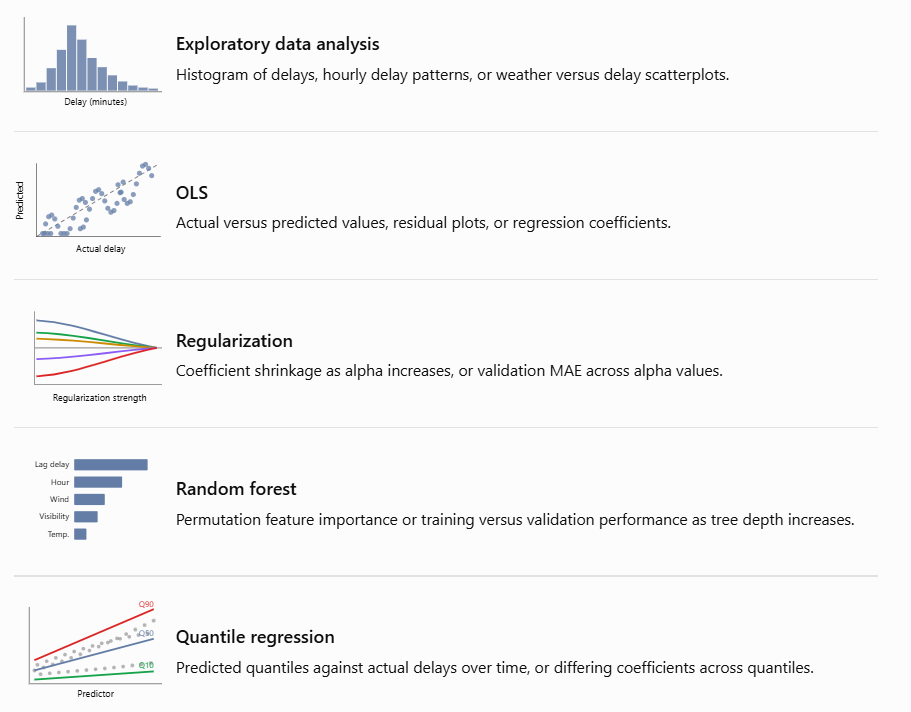